# Filter bandwidth: what does the fEPSP look like with different low-pass cutoffs?

Loads one ABF file and compares the signal unfiltered and low-pass filtered at 500, 300, 100, 50 and 30 Hz.

Same preprocessing as in `fp_analysis.py`: the stimulus artifact is blanked (linear interpolation), then a 4th-order Butterworth is applied (low-pass at each cutoff, plus a high-pass at `HIGHPASS` Hz, i.e. band-pass) with `sosfiltfilt` (zero phase shift, but effectively double the order), and finally the pre-stimulus baseline is subtracted.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyabf
from pathlib import Path
from scipy.signal import welch

from fp_analysis import (stim_time_s, preprocess, blank_artifact, find_slope_window,
                         compute_slope, BASELINE_WINDOW_S)

%matplotlib inline

## Settings

In [2]:
FILE = Path("acute") / "120826" / "12082026_FP_SR_cell2_activation_0012.abf"   # change to another file/experiment here

CUTOFFS = [None, 500, 300, 100, 50, 30]   # None = unfiltered (artifact blanking + baseline only)
PLOT_WINDOW_MS = (-5, 40)                 # relative to stimulus
FEPSP_SEARCH_MS = (3.0, 20.0)             # fEPSP search window (after fibre volley)
REF_CUTOFF = 1000                         # slope window is defined once on this filter and kept fixed
HIGHPASS = 5                           # high-pass cutoff (Hz) used together with every low-pass cutoff

def label(c):
    if c is None:
        return "unfiltered"
    return f"{HIGHPASS}–{c} Hz"

colors = dict(zip(CUTOFFS, plt.cm.viridis(np.linspace(0, 0.9, len(CUTOFFS)))))
colors[None] = "0.6"

## Load file

In [3]:
abf = pyabf.ABF(str(FILE))
stim = stim_time_s(abf)
fs = abf.dataRate
units = abf.adcUnits[0]
print(f"{FILE.name}: {abf.sweepCount} sweeps, {fs} Hz sampling, {abf.sweepLengthSec:.2f} s, stim at {stim*1000:.2f} ms")

def filtered(sweep, cutoff):
    abf.setSweep(sweep, channel=0)
    t, y = abf.sweepX, abf.sweepY
    if cutoff is None:
        y = blank_artifact(t, y, stim)
        base = (t >= stim + BASELINE_WINDOW_S[0]) & (t < stim + BASELINE_WINDOW_S[1])
        return t, y - y[base].mean()
    return t, preprocess(t, y, stim, fs, cutoff=cutoff, highpass=HIGHPASS)

time = abf.sweepX
t_ms = (time - stim) * 1000
win = (t_ms >= PLOT_WINDOW_MS[0]) & (t_ms <= PLOT_WINDOW_MS[1])

# traces[cutoff] = array (sweeps x samples)
traces = {c: np.array([filtered(s, c)[1] for s in abf.sweepList]) for c in CUTOFFS + [REF_CUTOFF]}

12082026_FP_SR_cell2_activation_0012.abf: 12 sweeps, 20000 Hz sampling, 0.60 s, stim at 209.35 ms


## One sweep, one panel per cutoff
Unfiltered signal in grey behind for comparison.

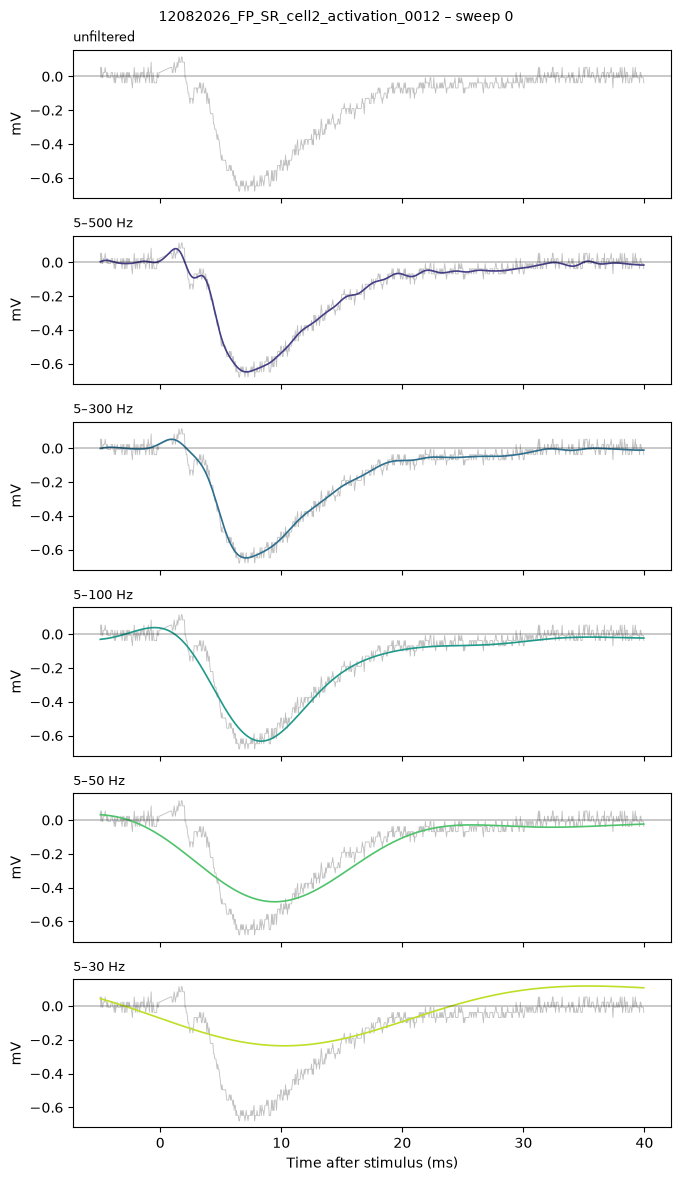

In [4]:
SWEEP = 0
fig, axes = plt.subplots(len(CUTOFFS), 1, figsize=(7, 2 * len(CUTOFFS)), sharex=True, sharey=True)
for ax, c in zip(axes, CUTOFFS):
    ax.plot(t_ms[win], traces[None][SWEEP][win], color="0.75", lw=0.6)
    if c is not None:
        ax.plot(t_ms[win], traces[c][SWEEP][win], color=colors[c], lw=1.2)
    ax.axhline(0, color="k", lw=0.3)
    ax.set_title(label(c), fontsize=9, loc="left")
    ax.set_ylabel(units)
axes[-1].set_xlabel("Time after stimulus (ms)")
fig.suptitle(f"{FILE.stem} – sweep {SWEEP}", fontsize=10)
fig.tight_layout()

## Mean of sweeps, all cutoffs overlaid

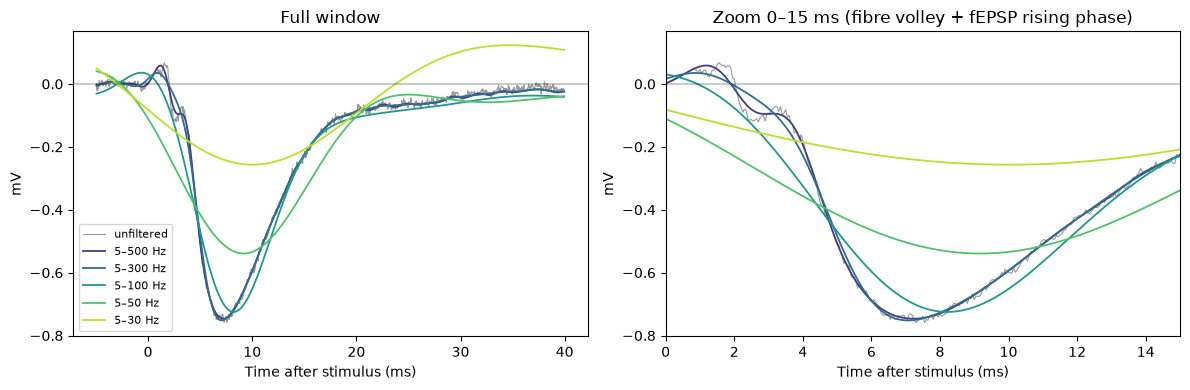

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c in CUTOFFS:
    m = traces[c].mean(axis=0)
    for a in ax:
        a.plot(t_ms[win], m[win], color=colors[c], lw=0.8 if c is None else 1.3, label=label(c))
for a in ax:
    a.axhline(0, color="k", lw=0.3)
    a.set_xlabel("Time after stimulus (ms)")
    a.set_ylabel(units)
ax[0].set_title("Full window")
ax[1].set_xlim(0, 15)
ax[1].set_title("Zoom 0–15 ms (fibre volley + fEPSP rising phase)")
ax[0].legend(fontsize=8)
fig.tight_layout()

## Quantification per cutoff
- **Baseline noise**: SD in a pre-stimulus window (50–200 ms before stim), averaged over sweeps
- **fEPSP amplitude and latency**: negative peak in the search window (mean trace)
- **Slope**: in a *fixed* window defined on the 1000 Hz reference, so any change is due to the filter only
- **SNR**: |amplitude| / baseline SD

In [6]:
ref_mean = traces[REF_CUTOFF].mean(axis=0)
slope_window = find_slope_window(time, ref_mean, stim, (FEPSP_SEARCH_MS[0] / 1000, FEPSP_SEARCH_MS[1] / 1000))
print("Slope window:", None if slope_window is None else f"{slope_window[0]*1000:.2f}–{slope_window[1]*1000:.2f} ms")

noise_mask = (time >= stim - 0.200) & (time < stim - 0.050)
search = (t_ms >= FEPSP_SEARCH_MS[0]) & (t_ms <= FEPSP_SEARCH_MS[1])

rows = []
for c in [REF_CUTOFF] + CUTOFFS:
    tr = traces[c]
    m = tr.mean(axis=0)
    noise = tr[:, noise_mask].std(axis=1).mean()
    i = np.argmin(m[search])
    amp = m[search][i]
    slopes = [compute_slope(time, s, stim, slope_window) for s in tr] if slope_window else [np.nan]
    rows.append({"cutoff": label(c),
                 "baseline SD": noise,
                 "fEPSP amp": amp,
                 "latency (ms)": t_ms[search][i],
                 "slope (/ms)": np.mean(slopes) / 1000,
                 "slope SD (/ms)": np.std(slopes) / 1000,
                 "SNR": abs(amp) / noise})
ref = rows[0]
for r in rows:
    r["amp % of ref"] = 100 * r["fEPSP amp"] / ref["fEPSP amp"]
    r["slope % of ref"] = 100 * r["slope (/ms)"] / ref["slope (/ms)"]
df = {r["cutoff"]: r for r in rows}

cols = [k for k in rows[0] if k != "cutoff"]
print(f"{'cutoff':>10} " + " ".join(f"{k:>15}" for k in cols))
for r in rows:
    print(f"{r['cutoff']:>10} " + " ".join(f"{r[k]:>15.4f}" for k in cols))

Slope window: 3.85–5.40 ms
    cutoff     baseline SD       fEPSP amp    latency (ms)     slope (/ms)  slope SD (/ms)             SNR    amp % of ref  slope % of ref
 5–1000 Hz          0.0178         -0.7458          7.5000         -0.2986          0.0116         41.8311        100.0000        100.0000
unfiltered          0.0273         -0.7588          7.3000         -0.3006          0.0140         27.7505        101.7457        100.6607
  5–500 Hz          0.0152         -0.7463          7.2500         -0.3009          0.0122         48.9782        100.0695        100.7538
  5–300 Hz          0.0142         -0.7519          7.0500         -0.2557          0.0118         52.9178        100.8103         85.6309
  5–100 Hz          0.0135         -0.7248          8.2000         -0.1430          0.0052         53.7341         97.1801         47.8777
   5–50 Hz          0.0130         -0.5391          9.2000         -0.0572          0.0018         41.3793         72.2807         19.1626


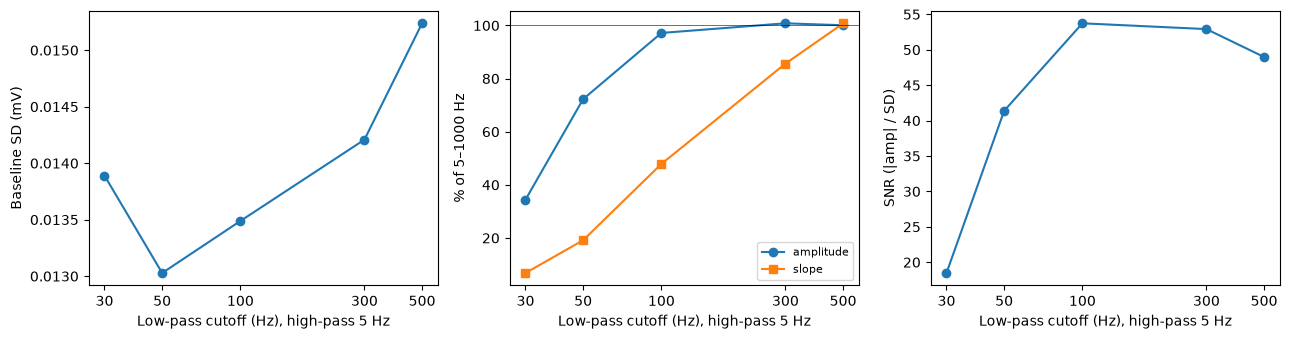

In [7]:
plot_c = [c for c in CUTOFFS if c is not None]
x = np.array(plot_c)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(x, [df[label(c)]["baseline SD"] for c in plot_c], "o-")
ax[0].set_ylabel(f"Baseline SD ({units})")
ax[1].plot(x, [df[label(c)]["amp % of ref"] for c in plot_c], "o-", label="amplitude")
ax[1].plot(x, [df[label(c)]["slope % of ref"] for c in plot_c], "s-", label="slope")
ax[1].axhline(100, color="k", lw=0.4)
ax[1].set_ylabel(f"% of {label(REF_CUTOFF)}")
ax[1].legend(fontsize=8)
ax[2].plot(x, [df[label(c)]["SNR"] for c in plot_c], "o-")
ax[2].set_ylabel("SNR (|amp| / SD)")
for a in ax:
    a.set_xscale("log")
    a.set_xticks(x)
    a.set_xticklabels(x)
    a.minorticks_off()
    a.set_xlabel(f"Low-pass cutoff (Hz), high-pass {HIGHPASS} Hz")
fig.tight_layout()

## Interpretation (notes)
- 500 Hz: amplitude and slope are unchanged, and noise drops by ~25 %. The fibre volley (~1–3 ms) is still visible.
- 300 Hz: amplitude unchanged, but slope is already ~−14 %. The rising phase is fast (slope window 3.85–5.40 ms, peak at ~7.5 ms), so it is sensitive to filtering. The fibre volley is smeared into a small bump.
- 100 Hz: amplitude ~−3 %, but slope is more than halved (48 %) and the peak comes ~0.7 ms later.
- 50 and 30 Hz: heavy distortion (amplitude 71 % / 35 %, slope 19 % / 7 % of reference). SNR still looks high, but at that point the filter is shaping the signal, not the response.
- The peak shifts later even with `filtfilt`, because the shape changes: the sharp peak is smoothed out and the broader underlying signal dominates.
- Amplitude survives filtering much better than slope: slope depends on the fast rising phase, which is the first thing a low-pass filter removes.
- The choice is a trade-off between noise reduction (baseline SD) and distortion of the response; see the `% of ref` columns. (Numbers above are for 12.08 cell2 SR, rec 12.)

## Sensor noise and limit of detection (LOD) per frequency
Values from the sensor characterisation table, by bias voltage (0, 0.5 and 1 V).
Two sensor designs, both 150 µm square: the original (more complicated) design, and the second version with suffix `_v2` (lower noise and LOD).
Suffix `_2x` = two sensor-1 devices combined: LOD scales as 1/√(number of sensors), so LOD / √2.

In [8]:
# sensor_table[frequency_Hz][column]; noise in nV/rtHz, LOD in nT/rtHz
# columns without suffix = sensor 1 (original design), "_v2" = sensor 2 (second version)
sensor_table = {
    10:   {"noise_0V": 9.90, "noise_0.5V": 19.73, "noise_1V": 44.81, "LOD_0.5V": 3.62, "LOD_1V": 4.15,
           "noise_0V_v2": 5.13, "noise_0.5V_v2": 14.27, "noise_1V_v2": 22.08, "LOD_0.5V_v2": 2.68, "LOD_1V_v2": 2.08},
    100:  {"noise_0V": 6.23, "noise_0.5V": 8.98,  "noise_1V": 13.13, "LOD_0.5V": 1.64, "LOD_1V": 1.21,
           "noise_0V_v2": 4.32, "noise_0.5V_v2": 6.06,  "noise_1V_v2": 9.40,  "LOD_0.5V_v2": 1.14, "LOD_1V_v2": 0.88},
    1000: {"noise_0V": 5.18, "noise_0.5V": 3.76,  "noise_1V": 5.56,  "LOD_0.5V": 0.68, "LOD_1V": 0.51,
           "noise_0V_v2": 3.44, "noise_0.5V_v2": 4.52,  "noise_1V_v2": 4.61,  "LOD_0.5V_v2": 0.87, "LOD_1V_v2": 0.43},
}

cols = list(sensor_table[10])
print(f"{'freq (Hz)':>10} " + " ".join(f"{k:>14}" for k in cols))
for f, row in sensor_table.items():
    print(f"{f:>10} " + " ".join(f"{row[k]:>14.2f}" for k in cols))

 freq (Hz)       noise_0V     noise_0.5V       noise_1V       LOD_0.5V         LOD_1V    noise_0V_v2  noise_0.5V_v2    noise_1V_v2    LOD_0.5V_v2      LOD_1V_v2
        10           9.90          19.73          44.81           3.62           4.15           5.13          14.27          22.08           2.68           2.08
       100           6.23           8.98          13.13           1.64           1.21           4.32           6.06           9.40           1.14           0.88
      1000           5.18           3.76           5.56           0.68           0.51           3.44           4.52           4.61           0.87           0.43


In [9]:
# Two sensors of version 1 combined: LOD scales as 1/sqrt(number of sensors)
N_SENSORS = 2
sensor_table_2x = {
    f: {f"{k}_2x": row[k] / np.sqrt(N_SENSORS) for k in ["LOD_0.5V", "LOD_1V"]}
    for f, row in sensor_table.items()
}
# add the new columns to sensor_table so S_B / band_area / find_N can use them via col="LOD_1V_2x"
for f in sensor_table:
    sensor_table[f].update(sensor_table_2x[f])

print(f"{'freq (Hz)':>10} " + " ".join(f"{k:>14}" for k in sensor_table_2x[10]))
for f, row in sensor_table_2x.items():
    print(f"{f:>10} " + " ".join(f"{row[k]:>14.2f}" for k in row))

 freq (Hz)    LOD_0.5V_2x      LOD_1V_2x
        10           2.56           2.93
       100           1.16           0.86
      1000           0.48           0.36


S_B(5)  = 6.01 nT/rtHz
S_B(50) = 1.75 nT/rtHz
sigma = 19.6 nT rms


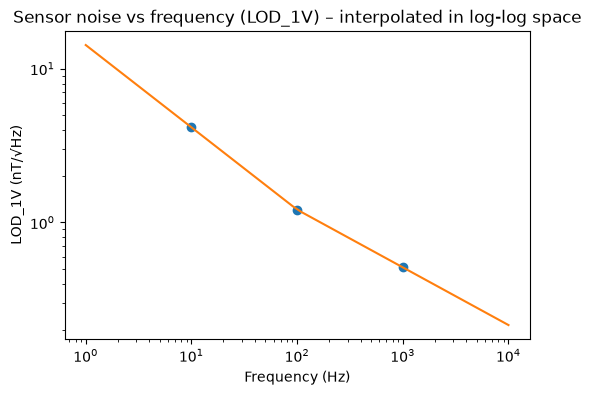

In [10]:
from scipy.interpolate import interp1d
from scipy.integrate import quad

col = "LOD_1V"
freqs = np.array(list(sensor_table))                     # [10, 100, 1000]
vals  = np.array([sensor_table[f][col] for f in freqs])  # [4.15, 1.21, 0.51]

# interpolate in log-log (= power law between points), extrapolate below 10 Hz
_loglog = interp1d(np.log10(freqs), np.log10(vals), kind="linear",
                   fill_value="extrapolate")

def S_B(f):
    return 10 ** _loglog(np.log10(f))

print(f"S_B(5)  = {S_B(5):.2f} nT/rtHz")   # 6.01
print(f"S_B(50) = {S_B(50):.2f} nT/rtHz")  # 1.75

# noise in the band (step 2 on the slides)
f1, f2 = 5, 50
var, _ = quad(lambda f: S_B(f)**2, f1, f2, points=[10, 100])
print(f"sigma = {np.sqrt(var):.1f} nT rms")  # 19.6

fig = plt.figure(figsize=(6, 4))
plt.loglog(freqs, vals, "o", label="sensor table")
plt.plot(np.logspace(0, 4), S_B(np.logspace(0, 4)), label="interpolated")
plt.xlabel("Frequency (Hz)")
plt.ylabel(f"{col} (nT/√Hz)")
plt.title(f"Sensor noise vs frequency ({col}) – interpolated in log-log space")
plt.show()

In [11]:
def S_B(f, col="LOD_1V"):
    """Noise density S_B(f), power law (log-log) between table points."""
    freqs = np.array(list(sensor_table))
    vals = np.array([sensor_table[fr][col] for fr in freqs])
    loglog = interp1d(np.log10(freqs), np.log10(vals), kind="linear",
                      fill_value="extrapolate")
    return 10 ** loglog(np.log10(f))

def noise_power(f, col="LOD_1V"):
    """Integrand: S_B(f)^2 in nT^2/Hz."""
    return S_B(f, col) ** 2

def band_area(f1, f2, col="LOD_1V", n=1000):
    """Area under S_B^2 from f1 to f2 = sigma^2 (nT^2). Returns (sigma^2, sigma).
    This is the same as the variance of the noise in the band f1–f2, and sigma is the RMS noise in that band.
    Wiener-Khinchin theorem: the area under the PSD is the variance of the signal."""

    f = np.logspace(np.log10(f1), np.log10(f2), n)   # frequency grid, dense at low f
    var = np.trapezoid(S_B(f, col) ** 2, f)          # area under the PSD
    return var, np.sqrt(var)

from fp_analysis import butter_lowpass

def signal_survival(cutoff, f1=HIGHPASS, measure="amp"):
    """a = fraction (0-1) of the fEPSP that survives filtering, relative to the unfiltered signal.
    cutoff = low-pass (Hz), f1 = high-pass (Hz) -> band-pass f1–cutoff.
    Uses the same filter as the fEPSP analysis above (fp_analysis.butter_lowpass).
    measure = "amp" or "slope"."""
    raw_mean = traces[None].mean(axis=0)
    base = (time >= stim + BASELINE_WINDOW_S[0]) & (time < stim + BASELINE_WINDOW_S[1])
    search = (time >= stim + FEPSP_SEARCH_MS[0] / 1000) & (time <= stim + FEPSP_SEARCH_MS[1] / 1000)

    def value(y):
        y = y - y[base].mean()
        return y[search].min() if measure == "amp" else compute_slope(time, y, stim, slope_window)

    return value(butter_lowpass(raw_mean, fs, cutoff=cutoff, highpass=f1)) / value(raw_mean)


def find_N(f1, f2, col="LOD_1V", SNR=3.0, B=0.5):
    """Find N = number of sweeps to average to achieve SNR in band f1–f2."""
    var, sigma = band_area(f1, f2, col)
    a = signal_survival(f2, f1=f1, measure="amp")  # fraction of fEPSP amplitude surviving band-pass f1–f2
    print(f"band {f1}-{f2} Hz: sigma = {sigma:.1f} nT rms, signal survival = {a:.3f}, SNR = {SNR}, B = {B}")
    return (SNR * sigma / (a * B)) ** 2 



Sensor 1 (original): area = 384 nT^2,  sigma = 19.6 nT rms
band 5-50 Hz: sigma = 19.6 nT rms, signal survival = 0.710, SNR = 3.0, B = 0.5
Sensor 2 (v2): area = 113 nT^2,  sigma = 10.7 nT rms
band 5-50 Hz: sigma = 10.7 nT rms, signal survival = 0.710, SNR = 3.0, B = 0.5
2 × sensor 1: area = 192 nT^2,  sigma = 13.9 nT rms
band 5-50 Hz: sigma = 13.9 nT rms, signal survival = 0.710, SNR = 3.0, B = 0.5


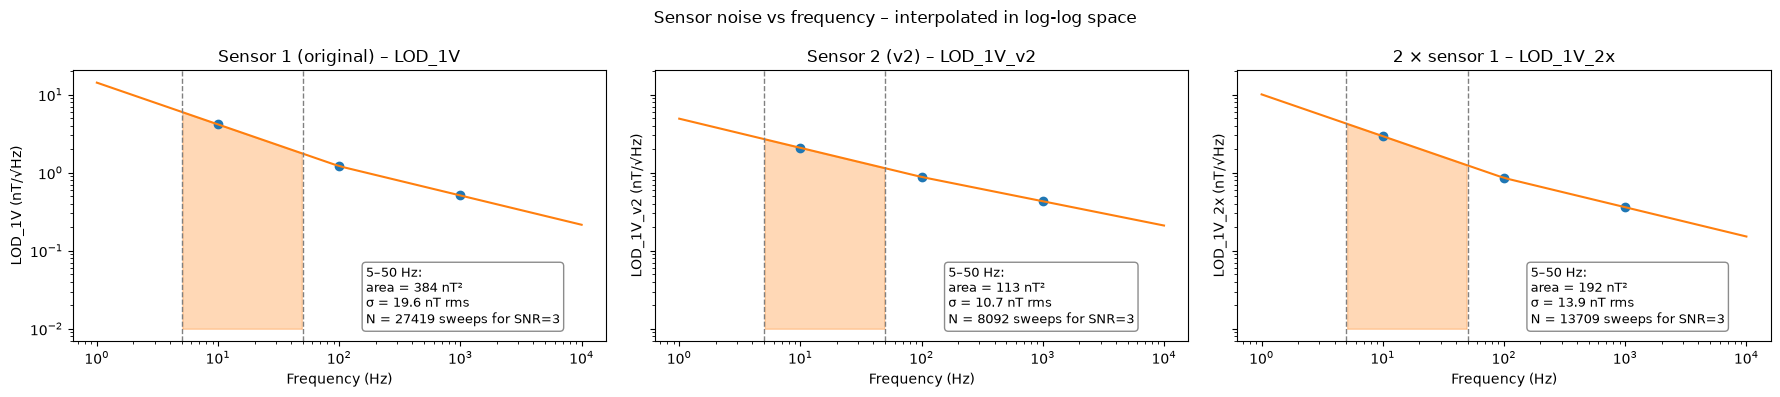

In [12]:
SENSORS = {"LOD_1V": "Sensor 1 (original)", "LOD_1V_v2": "Sensor 2 (v2)", "LOD_1V_2x": "2 × sensor 1"}
f1, f2 = 5, 50
fig, axes = plt.subplots(1, len(SENSORS), figsize=(6 * len(SENSORS), 4), sharey=True)
for ax, (col, name) in zip(axes, SENSORS.items()):
    v = np.array([sensor_table[fr][col] for fr in freqs])
    var, sigma = band_area(f1, f2, col)
    print(f"{name}: area = {var:.0f} nT^2,  sigma = {sigma:.1f} nT rms")
    ax.loglog(freqs, v, "o", label="sensor table")
    ax.plot(np.logspace(0, 4), S_B(np.logspace(0, 4), col), label="interpolated")
    ax.axvline(f1, color="0.5", ls="--", lw=1)
    ax.axvline(f2, color="0.5", ls="--", lw=1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(f"{col} (nT/√Hz)")
    ax.set_title(f"{name} – {col}")
    f = np.logspace(0, 4, 500)
    band = (f >= f1) & (f <= f2)
    ax.fill_between(f[band], S_B(f[band], col), 1e-2, alpha=0.3,
                    color="tab:orange", label=f"{f1}–{f2} Hz")
    ax.text(0.55, 0.05,
            f"{f1}–{f2} Hz:\narea = {var:.0f} nT²\nσ = {sigma:.1f} nT rms \nN = {find_N(f1, f2, col, SNR=3.0, B=0.5):.0f} sweeps for SNR=3",
            transform=ax.transAxes,      # position in axes coords (0–1), not data coords
            fontsize=9, va="bottom", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey", alpha=0.9))
fig.suptitle("Sensor noise vs frequency – interpolated in log-log space")
fig.tight_layout()
plt.show()

## f=5,100

Sensor 1 (original): area = 488 nT^2,  sigma = 22.1 nT rms
band 5-100 Hz: sigma = 22.1 nT rms, signal survival = 0.955, SNR = 3.0, B = 0.5
Sensor 2 (v2): area = 163 nT^2,  sigma = 12.8 nT rms
band 5-100 Hz: sigma = 12.8 nT rms, signal survival = 0.955, SNR = 3.0, B = 0.5
2 × sensor 1: area = 244 nT^2,  sigma = 15.6 nT rms
band 5-100 Hz: sigma = 15.6 nT rms, signal survival = 0.955, SNR = 3.0, B = 0.5


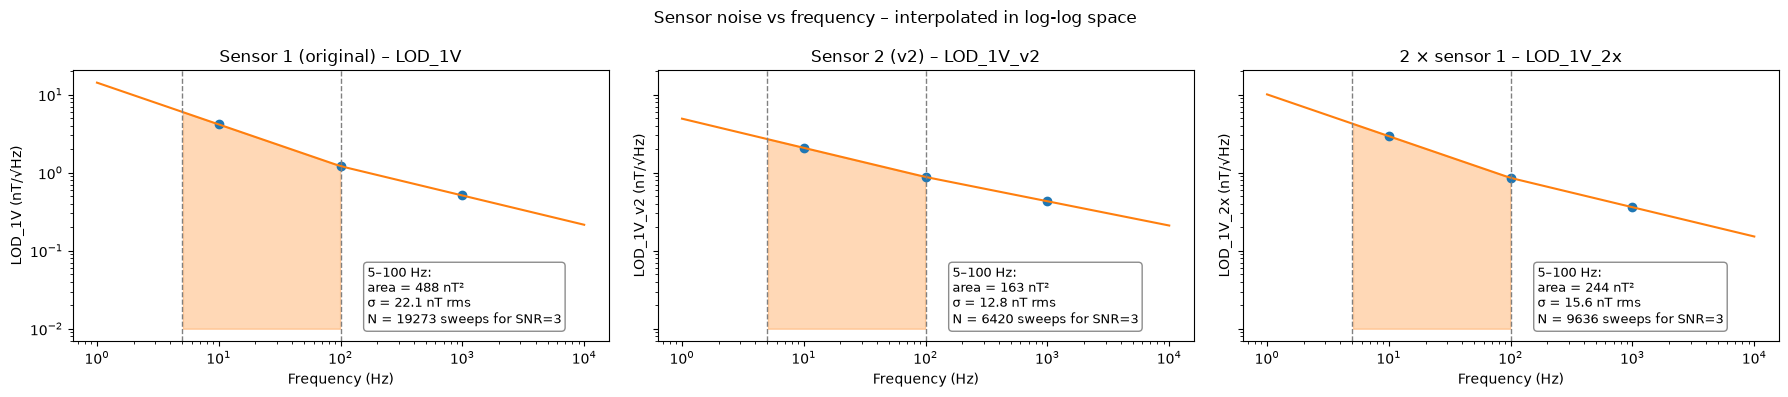

In [13]:
SENSORS = {"LOD_1V": "Sensor 1 (original)", "LOD_1V_v2": "Sensor 2 (v2)", "LOD_1V_2x": "2 × sensor 1"}
f1, f2 = 5, 100
fig, axes = plt.subplots(1, len(SENSORS), figsize=(6 * len(SENSORS), 4), sharey=True)
for ax, (col, name) in zip(axes, SENSORS.items()):
    v = np.array([sensor_table[fr][col] for fr in freqs])
    var, sigma = band_area(f1, f2, col)
    print(f"{name}: area = {var:.0f} nT^2,  sigma = {sigma:.1f} nT rms")
    ax.loglog(freqs, v, "o", label="sensor table")
    ax.plot(np.logspace(0, 4), S_B(np.logspace(0, 4), col), label="interpolated")
    ax.axvline(f1, color="0.5", ls="--", lw=1)
    ax.axvline(f2, color="0.5", ls="--", lw=1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(f"{col} (nT/√Hz)")
    ax.set_title(f"{name} – {col}")
    f = np.logspace(0, 4, 500)
    band = (f >= f1) & (f <= f2)
    ax.fill_between(f[band], S_B(f[band], col), 1e-2, alpha=0.3,
                    color="tab:orange", label=f"{f1}–{f2} Hz")
    ax.text(0.55, 0.05,
            f"{f1}–{f2} Hz:\narea = {var:.0f} nT²\nσ = {sigma:.1f} nT rms \nN = {find_N(f1, f2, col, SNR=3.0, B=0.5):.0f} sweeps for SNR=3",
            transform=ax.transAxes,      # position in axes coords (0–1), not data coords
            fontsize=9, va="bottom", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey", alpha=0.9))
fig.suptitle("Sensor noise vs frequency – interpolated in log-log space")
fig.tight_layout()
plt.show()

Sensor 1 (original): area = 304 nT^2,  sigma = 17.4 nT rms
band 5-30 Hz: sigma = 17.4 nT rms, signal survival = 0.338, SNR = 3.0, B = 0.5
Sensor 2 (v2): area = 82 nT^2,  sigma = 9.1 nT rms
band 5-30 Hz: sigma = 9.1 nT rms, signal survival = 0.338, SNR = 3.0, B = 0.5
2 × sensor 1: area = 152 nT^2,  sigma = 12.3 nT rms
band 5-30 Hz: sigma = 12.3 nT rms, signal survival = 0.338, SNR = 3.0, B = 0.5


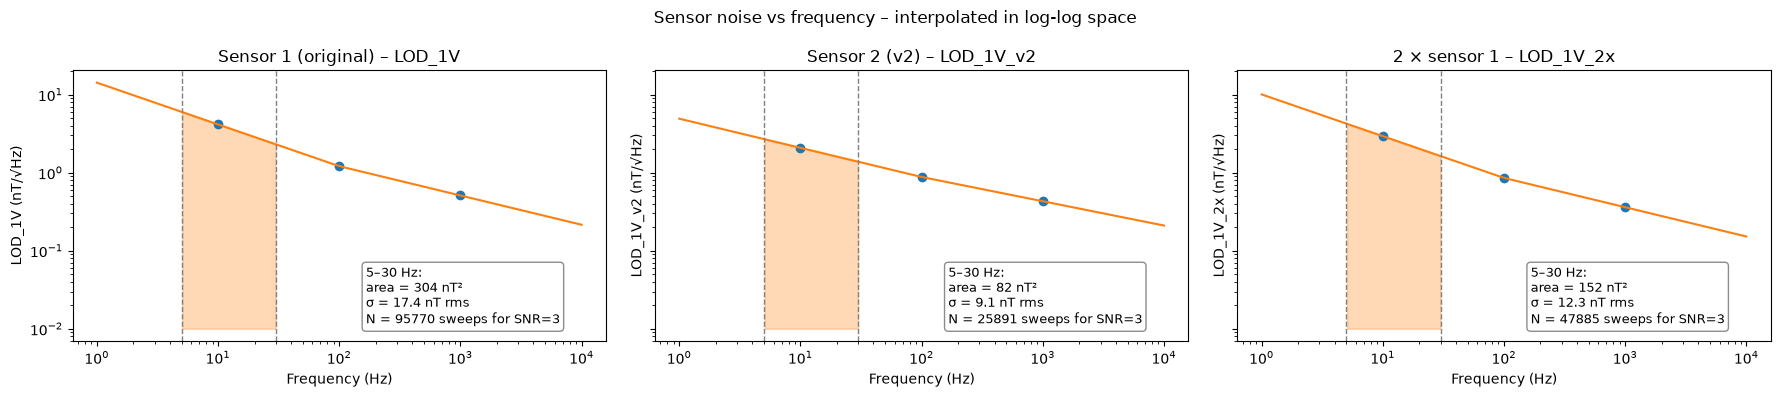

In [14]:
SENSORS = {"LOD_1V": "Sensor 1 (original)", "LOD_1V_v2": "Sensor 2 (v2)", "LOD_1V_2x": "2 × sensor 1"}
f1, f2 = 5, 30
fig, axes = plt.subplots(1, len(SENSORS), figsize=(6 * len(SENSORS), 4), sharey=True)
for ax, (col, name) in zip(axes, SENSORS.items()):
    v = np.array([sensor_table[fr][col] for fr in freqs])
    var, sigma = band_area(f1, f2, col)
    print(f"{name}: area = {var:.0f} nT^2,  sigma = {sigma:.1f} nT rms")
    ax.loglog(freqs, v, "o", label="sensor table")
    ax.plot(np.logspace(0, 4), S_B(np.logspace(0, 4), col), label="interpolated")
    ax.axvline(f1, color="0.5", ls="--", lw=1)
    ax.axvline(f2, color="0.5", ls="--", lw=1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(f"{col} (nT/√Hz)")
    ax.set_title(f"{name} – {col}")
    f = np.logspace(0, 4, 500)
    band = (f >= f1) & (f <= f2)
    ax.fill_between(f[band], S_B(f[band], col), 1e-2, alpha=0.3,
                    color="tab:orange", label=f"{f1}–{f2} Hz")
    ax.text(0.55, 0.05,
            f"{f1}–{f2} Hz:\narea = {var:.0f} nT²\nσ = {sigma:.1f} nT rms \nN = {find_N(f1, f2, col, SNR=3.0, B=0.5):.0f} sweeps for SNR=3",
            transform=ax.transAxes,      # position in axes coords (0–1), not data coords
            fontsize=9, va="bottom", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey", alpha=0.9))
fig.suptitle("Sensor noise vs frequency – interpolated in log-log space")
fig.tight_layout()
plt.show()

Sensor 1 (original): area = 673 nT^2,  sigma = 26.0 nT rms
band 5-300 Hz: sigma = 26.0 nT rms, signal survival = 0.991, SNR = 3.0, B = 0.5
Sensor 2 (v2): area = 268 nT^2,  sigma = 16.4 nT rms
band 5-300 Hz: sigma = 16.4 nT rms, signal survival = 0.991, SNR = 3.0, B = 0.5
2 × sensor 1: area = 337 nT^2,  sigma = 18.3 nT rms
band 5-300 Hz: sigma = 18.3 nT rms, signal survival = 0.991, SNR = 3.0, B = 0.5


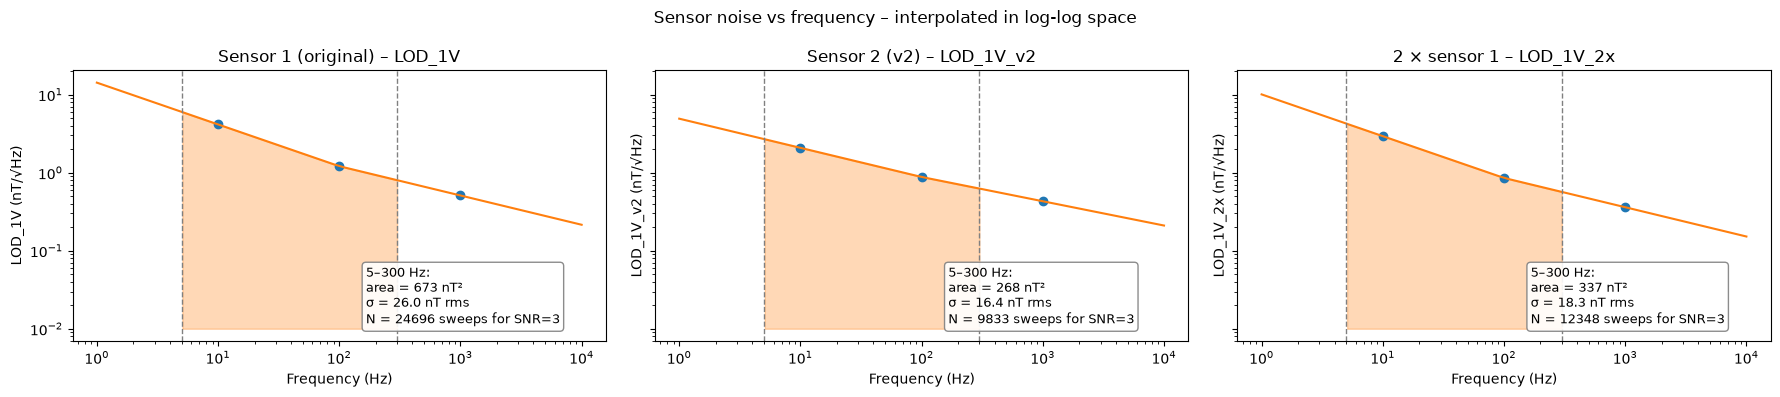

In [15]:
SENSORS = {"LOD_1V": "Sensor 1 (original)", "LOD_1V_v2": "Sensor 2 (v2)", "LOD_1V_2x": "2 × sensor 1"}
f1, f2 = 5, 300
fig, axes = plt.subplots(1, len(SENSORS), figsize=(6 * len(SENSORS), 4), sharey=True)
for ax, (col, name) in zip(axes, SENSORS.items()):
    v = np.array([sensor_table[fr][col] for fr in freqs])
    var, sigma = band_area(f1, f2, col)
    print(f"{name}: area = {var:.0f} nT^2,  sigma = {sigma:.1f} nT rms")
    ax.loglog(freqs, v, "o", label="sensor table")
    ax.plot(np.logspace(0, 4), S_B(np.logspace(0, 4), col), label="interpolated")
    ax.axvline(f1, color="0.5", ls="--", lw=1)
    ax.axvline(f2, color="0.5", ls="--", lw=1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(f"{col} (nT/√Hz)")
    ax.set_title(f"{name} – {col}")
    f = np.logspace(0, 4, 500)
    band = (f >= f1) & (f <= f2)
    ax.fill_between(f[band], S_B(f[band], col), 1e-2, alpha=0.3,
                    color="tab:orange", label=f"{f1}–{f2} Hz")
    ax.text(0.55, 0.05,
            f"{f1}–{f2} Hz:\narea = {var:.0f} nT²\nσ = {sigma:.1f} nT rms \nN = {find_N(f1, f2, col, SNR=3.0, B=0.5):.0f} sweeps for SNR=3",
            transform=ax.transAxes,      # position in axes coords (0–1), not data coords
            fontsize=9, va="bottom", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey", alpha=0.9))
fig.suptitle("Sensor noise vs frequency – interpolated in log-log space")
fig.tight_layout()
plt.show()

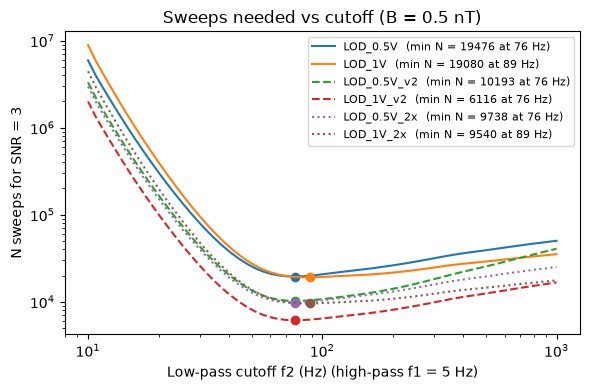

In [16]:
# N (sweeps needed for SNR = 3) vs low-pass cutoff f2, high-pass fixed at f1
SNR_TARGET = 3.0
B = 0.5                                       # fEPSP signal amplitude in nT
f1 = 5                                        # high-pass cutoff (Hz)
f2_grid = np.logspace(np.log10(10), np.log10(1000), 60)

fig, ax = plt.subplots(figsize=(6, 4))
for col in ["LOD_0.5V", "LOD_1V", "LOD_0.5V_v2", "LOD_1V_v2", "LOD_0.5V_2x", "LOD_1V_2x"]:   # sensor 1 solid, "_v2" dashed, "_2x" dotted
    N = []
    for f2 in f2_grid:
        _, sigma = band_area(f1, f2, col)
        a = signal_survival(f2, f1=f1, measure="amp")
        N.append((SNR_TARGET * sigma / (a * B)) ** 2)
    N = np.array(N)
    i = np.argmin(N)
    line, = ax.loglog(f2_grid, N, ls="--" if col.endswith("_v2") else ":" if col.endswith("_2x") else "-", label=f"{col}  (min N = {N[i]:.0f} at {f2_grid[i]:.0f} Hz)")
    ax.plot(f2_grid[i], N[i], "o", color=line.get_color())
ax.set_xlabel(f"Low-pass cutoff f2 (Hz) (high-pass f1 = {f1} Hz)")
ax.set_ylabel(f"N sweeps for SNR = {SNR_TARGET:g}")
ax.set_title(f"Sweeps needed vs cutoff (B = {B:g} nT)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


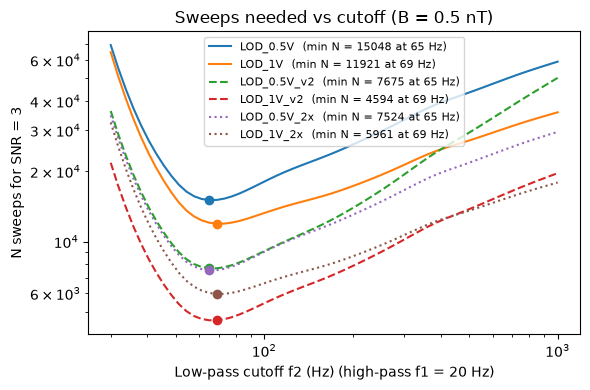

In [17]:
# N (sweeps needed for SNR = 3) vs low-pass cutoff f2, high-pass fixed at f1
SNR_TARGET = 3.0
B = 0.5                                       # fEPSP signal amplitude in nT
f1 = 20                                       # high-pass cutoff (Hz)
f2_grid = np.logspace(np.log10(f1 * 1.5), np.log10(1000), 60)

fig, ax = plt.subplots(figsize=(6, 4))
for col in ["LOD_0.5V", "LOD_1V", "LOD_0.5V_v2", "LOD_1V_v2", "LOD_0.5V_2x", "LOD_1V_2x"]:   # sensor 1 solid, "_v2" dashed, "_2x" dotted
    N = []
    for f2 in f2_grid:
        _, sigma = band_area(f1, f2, col)
        a = signal_survival(f2, f1=f1, measure="amp")
        N.append((SNR_TARGET * sigma / (a * B)) ** 2)
    N = np.array(N)
    i = np.argmin(N)
    line, = ax.loglog(f2_grid, N, ls="--" if col.endswith("_v2") else ":" if col.endswith("_2x") else "-", label=f"{col}  (min N = {N[i]:.0f} at {f2_grid[i]:.0f} Hz)")
    ax.plot(f2_grid[i], N[i], "o", color=line.get_color())
ax.set_xlabel(f"Low-pass cutoff f2 (Hz) (high-pass f1 = {f1} Hz)")
ax.set_ylabel(f"N sweeps for SNR = {SNR_TARGET:g}")
ax.set_title(f"Sweeps needed vs cutoff (B = {B:g} nT)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Analysis is perfomed based on a single electrical recording. We could also test the robustness across different recordings

## Old sensor 

In [ ]:
# old sensor: noise in nV/rtHz, LOD in nT/rtHz (no 0 V values in the table)
sensor_table_old = {
    10:   {"noise_1V_old": 36.65, "noise_2V_old": 70.78, "LOD_1V_old": 1.96, "LOD_2V_old": 1.98},
    100:  {"noise_1V_old": 12.90, "noise_2V_old": 22.40, "LOD_1V_old": 0.78, "LOD_2V_old": 0.65},
    1000: {"noise_1V_old": 9.41,  "noise_2V_old": 11.74, "LOD_1V_old": 0.57, "LOD_2V_old": 0.32},
}
for f in sensor_table:
    sensor_table[f].update(sensor_table_old[f])

print(f"{'freq (Hz)':>10} " + " ".join(f"{k:>14}" for k in sensor_table_old[10]))
for f, row in sensor_table_old.items():
    print(f"{f:>10} " + " ".join(f"{row[k]:>14.2f}" for k in row))


In [ ]:
# noise in the band and N sweeps for SNR = 3, old sensor at 1 V and 2 V bias, for several bands
SENSORS_OLD = {"LOD_1V_old": "Old sensor, 1 V", "LOD_2V_old": "Old sensor, 2 V"}
BANDS = [(5, 30), (5, 50), (5, 100), (5, 300)]

fig, axes = plt.subplots(len(BANDS), len(SENSORS_OLD), figsize=(6 * len(SENSORS_OLD), 3.6 * len(BANDS)), sharey=True)
f = np.logspace(0, 4, 500)
for row, (f1, f2) in zip(axes, BANDS):
    for ax, (col, name) in zip(row, SENSORS_OLD.items()):
        v = np.array([sensor_table[fr][col] for fr in freqs])
        var, sigma = band_area(f1, f2, col)
        N = find_N(f1, f2, col, SNR=3.0, B=0.5)
        ax.loglog(freqs, v, "o", label="sensor table")
        ax.plot(f, S_B(f, col), label="interpolated")
        ax.axvline(f1, color="0.5", ls="--", lw=1)
        ax.axvline(f2, color="0.5", ls="--", lw=1)
        band = (f >= f1) & (f <= f2)
        ax.fill_between(f[band], S_B(f[band], col), 1e-2, alpha=0.3, color="tab:orange", label=f"{f1}–{f2} Hz")
        ax.text(0.55, 0.05, f"{f1}–{f2} Hz:\narea = {var:.0f} nT²\nσ = {sigma:.1f} nT rms\nN = {N:.0f} sweeps for SNR=3",
                transform=ax.transAxes, fontsize=9, va="bottom", ha="left",
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey", alpha=0.9))
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel(f"{col} (nT/√Hz)")
        ax.set_title(f"{name} – band {f1}–{f2} Hz")
fig.suptitle("Old sensor: noise vs frequency – interpolated in log-log space")
fig.tight_layout()
plt.show()


In [ ]:
# N (sweeps needed for SNR = 3) vs low-pass cutoff f2, old sensor; new sensors in grey for comparison
SNR_TARGET = 3.0
B = 0.5                                       # fEPSP signal amplitude in nT
f1 = 5                                        # high-pass cutoff (Hz)
f2_grid = np.logspace(np.log10(10), np.log10(1000), 60)

fig, ax = plt.subplots(figsize=(7, 4.5))
for col in ["LOD_1V_old", "LOD_2V_old", "LOD_1V", "LOD_1V_v2"]:
    N = []
    for f2 in f2_grid:
        _, sigma = band_area(f1, f2, col)
        a = signal_survival(f2, f1=f1, measure="amp")
        N.append((SNR_TARGET * sigma / (a * B)) ** 2)
    N = np.array(N)
    i = np.argmin(N)
    old = col.endswith("_old")
    style = dict(lw=1.8) if old else dict(color="0.6", lw=1, ls="--" if col.endswith("_v2") else "-")
    line, = ax.loglog(f2_grid, N, label=f"{col}  (min N = {N[i]:.0f} at {f2_grid[i]:.0f} Hz)", **style)
    ax.plot(f2_grid[i], N[i], "o", color=line.get_color())
ax.set_xlabel(f"Low-pass cutoff f2 (Hz) (high-pass f1 = {f1} Hz)")
ax.set_ylabel(f"N sweeps for SNR = {SNR_TARGET:g}")
ax.set_title(f"Old sensor: sweeps needed vs cutoff (B = {B:g} nT)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


In [ ]:
# N (sweeps needed for SNR = 3) vs low-pass cutoff f2, old sensor; new sensors in grey for comparison
SNR_TARGET = 3.0
B = 0.5                                       # fEPSP signal amplitude in nT
f1 = 20                                        # high-pass cutoff (Hz)
f2_grid = np.logspace(np.log10(f1 * 1.5), np.log10(1000), 60)

fig, ax = plt.subplots(figsize=(7, 4.5))
for col in ["LOD_1V_old", "LOD_2V_old", "LOD_1V", "LOD_1V_v2"]:
    N = []
    for f2 in f2_grid:
        _, sigma = band_area(f1, f2, col)
        a = signal_survival(f2, f1=f1, measure="amp")
        N.append((SNR_TARGET * sigma / (a * B)) ** 2)
    N = np.array(N)
    i = np.argmin(N)
    old = col.endswith("_old")
    style = dict(lw=1.8) if old else dict(color="0.6", lw=1, ls="--" if col.endswith("_v2") else "-")
    line, = ax.loglog(f2_grid, N, label=f"{col}  (min N = {N[i]:.0f} at {f2_grid[i]:.0f} Hz)", **style)
    ax.plot(f2_grid[i], N[i], "o", color=line.get_color())
ax.set_xlabel(f"Low-pass cutoff f2 (Hz) (high-pass f1 = {f1} Hz)")
ax.set_ylabel(f"N sweeps for SNR = {SNR_TARGET:g}")
ax.set_title(f"Old sensor: sweeps needed vs cutoff (B = {B:g} nT)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## Old sensor: optimise f1 and f2 together
Colour map of N (sweeps needed for SNR = 3) over high-pass f1 and low-pass f2, with log colour scale. The minimum is marked with a star, and contours show where N is within 10 % and 50 % of the minimum (the "good enough" region).
Signal survival `a(f1, f2)` depends only on the filter and the fEPSP, so it is computed once and reused for both bias voltages. Combinations where f2 < 1.5·f1, or where the fEPSP is lost (a ≤ 0), are left blank.

In [ ]:
from matplotlib.colors import BoundaryNorm

SNR_TARGET = 3.0
B = 0.5                                                   # fEPSP signal amplitude in nT
SENSORS_OLD = {"LOD_1V_old": "Old sensor, 1 V", "LOD_2V_old": "Old sensor, 2 V"}
f1_grid = np.logspace(np.log10(1), np.log10(100), 30)     # high-pass (Hz)
f2_grid = np.logspace(np.log10(10), np.log10(1000), 40)   # low-pass (Hz)

# signal survival a(f1, f2): independent of the sensor, so compute once
valid = f2_grid[None, :] >= 1.5 * f1_grid[:, None]        # shape (f1, f2)
A = np.full(valid.shape, np.nan)
for i, f1 in enumerate(f1_grid):
    for j, f2 in enumerate(f2_grid):
        if valid[i, j]:
            A[i, j] = signal_survival(f2, f1=f1, measure="amp")
A[A <= 0] = np.nan

# N(f1, f2) per sensor
N_maps = {}
for col in SENSORS_OLD:
    sig = np.full(valid.shape, np.nan)
    for i, f1 in enumerate(f1_grid):
        for j, f2 in enumerate(f2_grid):
            if valid[i, j]:
                sig[i, j] = band_area(f1, f2, col)[1]
    N_maps[col] = (SNR_TARGET * sig / (A * B)) ** 2

# discrete levels in powers of 2, shared by both panels
vmin = min(np.nanmin(N) for N in N_maps.values())
levels = 2.0 ** np.arange(np.floor(np.log2(vmin)), np.floor(np.log2(vmin)) + 9)   # 8 bands = factor 256 above the minimum
cmap = plt.get_cmap("PuBuGn_r")
norm = BoundaryNorm(levels, cmap.N, extend="both")

fig, axes = plt.subplots(1, len(SENSORS_OLD), figsize=(6.5 * len(SENSORS_OLD), 5), sharey=True, constrained_layout=True)
for ax, (col, name) in zip(axes, SENSORS_OLD.items()):
    N = N_maps[col]
    ax.set_facecolor("0.85")                              # grey = no valid band (f2 < 1.5·f1, or fEPSP lost)
    cf = ax.contourf(f2_grid, f1_grid, N, levels=levels, cmap=cmap, norm=norm, extend="both")
    cl = ax.contour(f2_grid, f1_grid, N, levels=levels, colors="k", linewidths=0.5)
    ax.clabel(cl, fmt=lambda v: f"{v:.0f}", fontsize=8)
    i, j = np.unravel_index(np.nanargmin(N), N.shape)
    Nmin = N[i, j]
    ax.contour(f2_grid, f1_grid, N, levels=[1.1 * Nmin], colors="red", linewidths=1, linestyles="--")   # within +10 % of the minimum
    ax.plot(f2_grid[j], f1_grid[i], "*", color="red", ms=14, mec="k")
    ax.text(0.04, 0.96, "f2 < 1.5·f1\n(no valid band)", transform=ax.transAxes, va="top", fontsize=8, color="0.3")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Low-pass cutoff f2 (Hz)")
    ax.set_title(f"{name}\nmin N = {Nmin:.0f} at f1 = {f1_grid[i]:.1f} Hz, f2 = {f2_grid[j]:.0f} Hz  (a = {A[i, j]:.2f})", fontsize=10)
    print(f"{name}: min N = {Nmin:.1f} at f1 = {f1_grid[i]:.2f} Hz, f2 = {f2_grid[j]:.1f} Hz, "
          f"sigma = {band_area(f1_grid[i], f2_grid[j], col)[1]:.1f} nT rms, a = {A[i, j]:.3f}")
axes[0].set_ylabel("High-pass cutoff f1 (Hz)")
cb = fig.colorbar(cf, ax=axes, ticks=levels, label=f"N sweeps for SNR = {SNR_TARGET:g} (B = {B:g} nT)")
cb.ax.set_yticklabels([f"{v:.0f}" for v in levels])
fig.suptitle("Old sensor: sweeps needed vs high-pass f1 and low-pass f2  (red star = minimum, red dashed = +10 %)")
plt.show()

## New designs: V3 and V4
Estimated noise and LOD for two new designs. These are *estimated from v2*, not measured.
- **V3**: 2 elements, 76 Ω, 42 000 µm²
- **V4**: 4 elements, 333 Ω, 38 400 µm²

Column names: `LOD_0.5V_v3`, `LOD_1V_v3`, `LOD_0.5V_v4`, `LOD_1V_v4`. The table has no LOD at 0 V.

![V3/V4 noise and LOD table](figures/sensor_v3_v4_table.png)

![V3/V4 element layout](figures/sensor_v3_v4_layout.png)

In [ ]:
# V3 and V4 (estimated from v2): noise in nV/rtHz, LOD in nT/rtHz
sensor_table_v34 = {
    10:   {"noise_0V_v3": 2.37, "noise_0.5V_v3": 6.60, "noise_1V_v3": 10.21, "LOD_0.5V_v3": 1.24, "LOD_1V_v3": 0.96,
           "noise_0V_v4": 2.48, "noise_0.5V_v4": 6.90, "noise_1V_v4": 10.68, "LOD_0.5V_v4": 1.29, "LOD_1V_v4": 1.00},
    100:  {"noise_0V_v3": 1.99, "noise_0.5V_v3": 2.80, "noise_1V_v3": 4.34,  "LOD_0.5V_v3": 0.52, "LOD_1V_v3": 0.41,
           "noise_0V_v4": 2.09, "noise_0.5V_v4": 2.93, "noise_1V_v4": 4.54,  "LOD_0.5V_v4": 0.55, "LOD_1V_v4": 0.42},
    1000: {"noise_0V_v3": 1.59, "noise_0.5V_v3": 2.09, "noise_1V_v3": 2.13,  "LOD_0.5V_v3": 0.40, "LOD_1V_v3": 0.19,
           "noise_0V_v4": 1.66, "noise_0.5V_v4": 2.18, "noise_1V_v4": 2.23,  "LOD_0.5V_v4": 0.42, "LOD_1V_v4": 0.20},
}
for f in sensor_table:
    sensor_table[f].update(sensor_table_v34[f])

print(f"{'freq (Hz)':>10} " + " ".join(f"{k:>14}" for k in sensor_table_v34[10]))
for f, row in sensor_table_v34.items():
    print(f"{f:>10} " + " ".join(f"{row[k]:>14.2f}" for k in row))

In [ ]:
# noise in the band and N sweeps for SNR = 3, V3 and V4 at 1 V bias, for several bands
SENSORS_V34 = {"LOD_1V_v3": "V3, 1 V", "LOD_1V_v4": "V4, 1 V"}
BANDS = [(5, 30), (5, 50), (5, 100), (5, 300)]

fig, axes = plt.subplots(len(BANDS), len(SENSORS_V34), figsize=(6 * len(SENSORS_V34), 3.6 * len(BANDS)), sharey=True)
f = np.logspace(0, 4, 500)
for row, (f1, f2) in zip(axes, BANDS):
    for ax, (col, name) in zip(row, SENSORS_V34.items()):
        v = np.array([sensor_table[fr][col] for fr in freqs])
        var, sigma = band_area(f1, f2, col)
        N = find_N(f1, f2, col, SNR=3.0, B=0.5)
        ax.loglog(freqs, v, "o", label="sensor table")
        ax.plot(f, S_B(f, col), label="interpolated")
        ax.axvline(f1, color="0.5", ls="--", lw=1)
        ax.axvline(f2, color="0.5", ls="--", lw=1)
        band = (f >= f1) & (f <= f2)
        ax.fill_between(f[band], S_B(f[band], col), 1e-2, alpha=0.3, color="tab:orange", label=f"{f1}–{f2} Hz")
        ax.text(0.55, 0.05, f"{f1}–{f2} Hz:\narea = {var:.0f} nT²\nσ = {sigma:.1f} nT rms\nN = {N:.0f} sweeps for SNR=3",
                transform=ax.transAxes, fontsize=9, va="bottom", ha="left",
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey", alpha=0.9))
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel(f"{col} (nT/√Hz)")
        ax.set_title(f"{name} – band {f1}–{f2} Hz")
fig.suptitle("V3 and V4: noise vs frequency – interpolated in log-log space")
fig.tight_layout()
plt.show()

In [ ]:
# N (sweeps needed for SNR = 3) vs low-pass cutoff f2 for V3/V4; old sensor and v2 in grey for comparison
SNR_TARGET = 3.0
B = 0.5                                       # fEPSP signal amplitude in nT
COMPARE = ["LOD_0.5V_v3", "LOD_1V_v3", "LOD_0.5V_v4", "LOD_1V_v4", "LOD_2V_old", "LOD_1V_v2"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, f1 in zip(axes, [5, 20]):
    f2_line = np.logspace(np.log10(max(10, f1 * 1.5)), np.log10(1000), 60)
    a_line = np.array([signal_survival(f2, f1=f1, measure="amp") for f2 in f2_line])   # same for every sensor
    for col in COMPARE:
        sig = np.array([band_area(f1, f2, col)[1] for f2 in f2_line])
        N = (SNR_TARGET * sig / (a_line * B)) ** 2
        i = np.argmin(N)
        new = col.endswith(("_v3", "_v4"))
        style = (dict(lw=1.8, ls="-" if col.endswith("_v3") else "--") if new
                 else dict(color="0.6", lw=1, ls=":" if col.endswith("_old") else "-."))
        line, = ax.loglog(f2_line, N, label=f"{col}  (min N = {N[i]:.0f} at {f2_line[i]:.0f} Hz)", **style)
        ax.plot(f2_line[i], N[i], "o", color=line.get_color())
    ax.set_xlabel(f"Low-pass cutoff f2 (Hz) (high-pass f1 = {f1} Hz)")
    ax.set_title(f"f1 = {f1} Hz")
    ax.legend(fontsize=7)
axes[0].set_ylabel(f"N sweeps for SNR = {SNR_TARGET:g}")
fig.suptitle(f"V3 and V4: sweeps needed vs cutoff (B = {B:g} nT); V3 solid, V4 dashed, old 2 V and v2 1 V in grey")
fig.tight_layout()
plt.show()

In [ ]:
# V3 and V4: optimise f1 and f2 together (same method and style as the old-sensor colour map above).
# Reuses f1_grid, f2_grid, valid and A (signal survival) from the old-sensor cell, since A does not depend on the sensor.
SENSORS_V34 = {"LOD_0.5V_v3": "V3, 0.5 V", "LOD_1V_v3": "V3, 1 V", "LOD_0.5V_v4": "V4, 0.5 V", "LOD_1V_v4": "V4, 1 V"}

N_maps_v34 = {}
for col in SENSORS_V34:
    sig = np.full(valid.shape, np.nan)
    for i, f1 in enumerate(f1_grid):
        for j, f2 in enumerate(f2_grid):
            if valid[i, j]:
                sig[i, j] = band_area(f1, f2, col)[1]
    N_maps_v34[col] = (SNR_TARGET * sig / (A * B)) ** 2

vmin = min(np.nanmin(N) for N in N_maps_v34.values())
levels = 2.0 ** np.arange(np.floor(np.log2(vmin)), np.floor(np.log2(vmin)) + 9)   # 8 bands = factor 256 above the minimum
cmap = plt.get_cmap("PuBuGn_r")
norm = BoundaryNorm(levels, cmap.N, extend="both")

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True, constrained_layout=True)
for ax, (col, name) in zip(axes.flat, SENSORS_V34.items()):
    N = N_maps_v34[col]
    ax.set_facecolor("0.85")                              # grey = no valid band (f2 < 1.5·f1, or fEPSP lost)
    cf = ax.contourf(f2_grid, f1_grid, N, levels=levels, cmap=cmap, norm=norm, extend="both")
    cl = ax.contour(f2_grid, f1_grid, N, levels=levels, colors="k", linewidths=0.5)
    ax.clabel(cl, fmt=lambda v: f"{v:.0f}", fontsize=8)
    i, j = np.unravel_index(np.nanargmin(N), N.shape)
    Nmin = N[i, j]
    ax.contour(f2_grid, f1_grid, N, levels=[1.1 * Nmin], colors="red", linewidths=1, linestyles="--")   # within +10 % of the minimum
    ax.plot(f2_grid[j], f1_grid[i], "*", color="red", ms=14, mec="k")
    ax.text(0.04, 0.96, "f2 < 1.5·f1\n(no valid band)", transform=ax.transAxes, va="top", fontsize=8, color="0.3")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{name}\nmin N = {Nmin:.0f} at f1 = {f1_grid[i]:.1f} Hz, f2 = {f2_grid[j]:.0f} Hz  (a = {A[i, j]:.2f})", fontsize=10)
    print(f"{name}: min N = {Nmin:.1f} at f1 = {f1_grid[i]:.2f} Hz, f2 = {f2_grid[j]:.1f} Hz, "
          f"sigma = {band_area(f1_grid[i], f2_grid[j], col)[1]:.1f} nT rms, a = {A[i, j]:.3f}")
for ax in axes[-1]:
    ax.set_xlabel("Low-pass cutoff f2 (Hz)")
for ax in axes[:, 0]:
    ax.set_ylabel("High-pass cutoff f1 (Hz)")
cb = fig.colorbar(cf, ax=axes, ticks=levels, label=f"N sweeps for SNR = {SNR_TARGET:g} (B = {B:g} nT)")
cb.ax.set_yticklabels([f"{v:.0f}" for v in levels])
fig.suptitle("V3 and V4: sweeps needed vs high-pass f1 and low-pass f2  (red star = minimum, red dashed = +10 %)")
plt.show()